# Probabilistic FDM — Heat Equation (2D Matérnカーネル)

PDE: $\partial_t u = \partial_{xx} u$, $u(t,0)=u(t,1)=0$, $u(0,x)=\sin(\pi x)$

真の解: $u(t,x) = e^{-\pi^2 t}\sin(\pi x)$

Backward Euler + 空間中心差分。全時間ステップをスタックして一つの線形系 $D_h \mathbf{u} = \mathbf{f}$ を構成し、2D GP事後分布を求める。

In [31]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics

## 1. 2D Matérnカーネル・問題設定

In [32]:
# 2D Matérn kernel: 入力は (t, x) ∈ R^2
# 異方的カーネル: 時間・空間で別の長さスケール ℓt, ℓx
function matern_kernel_2d(p1, p2; ν=1.0, ℓt=1.0, ℓx=1.0)
    r = sqrt(((p1[1]-p2[1])/ℓt)^2 + ((p1[2]-p2[2])/ℓx)^2)
    r == 0 && return 1.0
    z = sqrt(2ν) * r
    if ν == 0.5
        return exp(-z)
    elseif ν == 1.5
        return (1 + z) * exp(-z)
    elseif ν == 2.5
        return (1 + z + z^2/3) * exp(-z)
    else
        return (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_2d(P1, P2; ν=1.0, ℓt=1.0, ℓx=1.0)
    [matern_kernel_2d(p1, p2; ν=ν, ℓt=ℓt, ℓx=ℓx) for p1 in P1, p2 in P2]
end

# 問題設定
u_exact(t, x) = exp(-π^2 * t) * sin(π * x)
u0_func(x)    = sin(π * x)   # 初期条件

u0_func (generic function with 1 method)

## 2. 情報オペレータ $D_h$ の構成

In [33]:
# ============================================================
# D_h u = f の構造 (右辺 f に前時刻の標準FDM解を使う):
#   - t=0 の行: u(0,x_i) = u0(x_i)                    [ノイズ=0]
#   - t=n の境界行: u(t_n,0)=0, u(t_n,1)=0             [ノイズ=0]
#   - t=n の内点行: (I-dt*Δ_h) u^n = u^{n-1}_fdm       [ノイズ=C*h^{2τ}]
#     u^{n-1}_fdm は標準Backward Euler FDMの解 (既知として扱う)
# ============================================================

function build_fdm_solution(Nx, Nt, dx, dt)
    n_int = Nx - 1
    A = zeros(n_int, n_int)
    for i in 1:n_int
        A[i,i] = 1.0 + 2dt/dx^2
        if i > 1;      A[i,i-1] = -dt/dx^2; end
        if i < n_int;  A[i,i+1] = -dt/dx^2; end
    end
    u_all = zeros(Nt+1, Nx+1)
    for i in 0:Nx
        u_all[1, i+1] = u0_func(i*dx)
    end
    for n in 1:Nt
        rhs   = u_all[n, 2:end-1]
        u_int = A \ rhs
        u_all[n+1, :] = vcat(0.0, u_int, 0.0)
    end
    return u_all
end

function build_system(Nx, Nt, dx, dt)
    n_per_step = Nx + 1
    N_total    = (Nt + 1) * n_per_step

    points = Tuple{Float64,Float64}[]
    for n in 0:Nt
        t_n = n * dt
        for i in 0:Nx
            push!(points, (t_n, i*dx))
        end
    end

    u_fdm    = build_fdm_solution(Nx, Nt, dx, dt)
    D        = zeros(N_total, N_total)
    f        = zeros(N_total)
    is_noise = trues(N_total)

    for n in 0:Nt
        row_offset = n * n_per_step
        if n == 0
            for i in 0:Nx
                row = row_offset + i + 1
                D[row, row] = 1.0
                f[row]      = u0_func(i*dx)
                is_noise[row] = false
            end
        else
            # 左境界
            row = row_offset + 1
            D[row, row] = 1.0;  f[row] = 0.0;  is_noise[row] = false
            # 右境界
            row = row_offset + Nx + 1
            D[row, row] = 1.0;  f[row] = 0.0;  is_noise[row] = false
            # 内点: (I - dt*Δ_h) u^n = u^{n-1}_fdm
            for i in 1:Nx-1
                row = row_offset + i + 1
                D[row, row_offset + i]     = -dt / dx^2
                D[row, row_offset + i + 1] =  1.0 + 2dt / dx^2
                D[row, row_offset + i + 2] = -dt / dx^2
                f[row] = u_fdm[n, i+1]   # u^{n-1}_fdm[x_i]
                is_noise[row] = true
            end
        end
    end

    return D, f, points, is_noise, N_total, u_fdm
end


build_system (generic function with 1 method)

## 3. log周辺尤度・事後分布

In [34]:
function log_marginal_heat(
    points, y, D, is_noise;
    ν, ℓt, ℓx, C, h, τ, jitter=1e-10
)
    n = length(points)
    noise_diag = [is_noise[i] ? C * h^(2τ) : 0.0 for i in 1:n]
    Σ = Diagonal(noise_diag)

    K     = kernel_matrix_2d(points, points; ν=ν, ℓt=ℓt, ℓx=ℓx)
    K_obs = D * K * D' + Σ + jitter * I

    local L
    try
        L = cholesky(Hermitian(K_obs)).L
    catch
        return -Inf
    end

    α       = L' \ (L \ y)
    logdetK = 2sum(log.(diag(L)))
    return -0.5*(y'*α) - 0.5*logdetK - 0.5*n*log(2π)
end

function run_pfdm_heat(points, y, D, is_noise, test_points;
                        ν, ℓt, ℓx, C, h, τ)
    n = length(points)
    noise_diag = [is_noise[i] ? C * h^(2τ) : 0.0 for i in 1:n]
    Σ = Diagonal(noise_diag)

    K     = kernel_matrix_2d(points, points; ν=ν, ℓt=ℓt, ℓx=ℓx)
    K_obs = D * K * D' + Σ + 1e-10 * I

    Ks  = kernel_matrix_2d(test_points, points; ν=ν, ℓt=ℓt, ℓx=ℓx) * D'
    Kss = kernel_matrix_2d(test_points, test_points; ν=ν, ℓt=ℓt, ℓx=ℓx)

    K_chol   = cholesky(Hermitian(K_obs))
    μ_post   = Ks * (K_chol \ y)
    Σ_post   = Kss - Ks * (K_chol \ Ks')
    std_post = sqrt.(max.(diag(Σ_post), 0.0))

    return μ_post, std_post
end

run_pfdm_heat (generic function with 1 method)

## 4. ハイパーパラメータ選択・事後分布の可視化

In [35]:
# ============================================================
# 設定
# ============================================================
Nx   = 20       # 空間グリッド数
Nt   = 10       # 時間ステップ数
T    = 1.0      # 終端時刻
dx   = 1.0 / Nx
dt   = T / Nt
h    = max(dx, dt)  # 代表刻み幅
ν_fixed = 1.0
τ_fixed = 2

D, f, points, is_noise, N_total, u_fdm = build_system(Nx, Nt, dx, dt)
println("N_total = $N_total, rank(D) check: det ≠ 0? $(abs(det(D)) > 1e-10)")

# ハイパーパラメータグリッドサーチ (異方的カーネル: ℓt, ℓx 独立)
ℓt_grid = [0.05, 0.1, 0.2, 0.3, 0.5]   # 時間スケール
ℓx_grid = [0.1, 0.2, 0.3, 0.5, 1.0]    # 空間スケール
C_grid  = 10 .^ range(-4, 1, length=8)

best_score = -Inf
best_ℓt = ℓt_grid[1]
best_ℓx = ℓx_grid[1]
best_C  = C_grid[1]

for ℓt in ℓt_grid, ℓx in ℓx_grid, C in C_grid
    score = log_marginal_heat(
        points, f, D, is_noise;
        ν=ν_fixed, ℓt=ℓt, ℓx=ℓx, C=C, h=h, τ=τ_fixed
    )
    if score > best_score
        best_score = score
        best_ℓt = ℓt
        best_ℓx = ℓx
        best_C  = C
    end
end
println("best ℓt=$(round(best_ℓt,sigdigits=3)), ℓx=$(round(best_ℓx,sigdigits=3)), C=$(round(best_C,sigdigits=3)), loglik=$(round(best_score,sigdigits=5))")

# 事後分布を計算
# テスト点: 各時間ステップで密な空間グリッド
# テスト点 = 訓練グリッド点と同じ (グリッド間補間による振動を避ける)
n_test_x = Nx + 1
x_test   = range(0.0, 1.0, length=n_test_x)
test_points = Tuple{Float64,Float64}[]
for n in 0:Nt
    t_n = n * dt
    for x in x_test
        push!(test_points, (t_n, x))
    end
end

μ_post, std_post = run_pfdm_heat(
    points, f, D, is_noise, test_points;
    ν=ν_fixed, ℓt=best_ℓt, ℓx=best_ℓx, C=best_C, h=h, τ=τ_fixed
)
println("Inference done.")
# 診断: FDM解と真の解の誤差
for n in 0:Nt
    t_n = n*dt
    err = maximum(abs.(u_fdm[n+1,:] .- [u_exact(t_n, i*dx) for i in 0:Nx]))
    println("  FDM err at t=$(round(t_n,digits=3)): $(round(err,sigdigits=3))")
end

N_total = 231, rank(D) check: det ≠ 0? true
best ℓt=0.5, ℓx=1.0, C=0.0001, loglik=-431.31
Inference done.
  FDM err at t=0.0: 0.0
  FDM err at t=0.1: 0.131
  FDM err at t=0.2: 0.115
  FDM err at t=0.3: 0.0761
  FDM err at t=0.4: 0.0451
  FDM err at t=0.5: 0.0253
  FDM err at t=0.6: 0.0137
  FDM err at t=0.7: 0.00724
  FDM err at t=0.8: 0.00378
  FDM err at t=0.9: 0.00195
  FDM err at t=1.0: 0.001


## 5. 可視化: 各時間ステップの事後分布

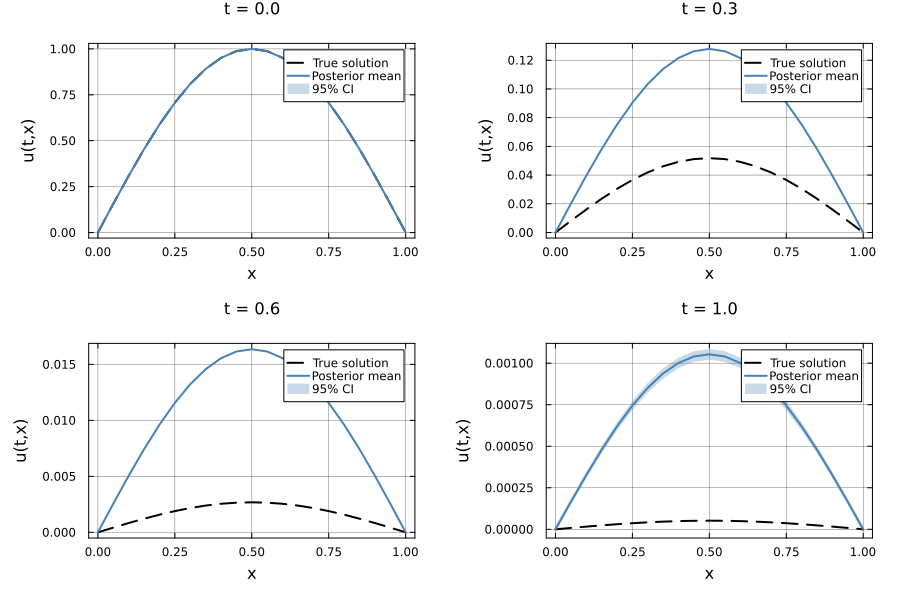

Saved: heat_matern_4panels.png


In [36]:
# 各時間ステップをパネルとして表示 (最大4パネル: t=0, T/3, 2T/3, T)
plot_steps = unique([0, div(Nt,3), div(2Nt,3), Nt])

plots_list = []
for n in plot_steps
    t_n   = n * dt
    idx   = (n * n_test_x + 1):(n * n_test_x + n_test_x)
    μ_n   = μ_post[idx]
    σ_n   = std_post[idx]
    u_true_n = [u_exact(t_n, x) for x in x_test]

    p = plot(
        collect(x_test), u_true_n;
        label="True solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(t,x)",
        title="t = $(round(t_n, digits=3))",
        titlefontsize=11, legendfontsize=8,
        grid=true, gridalpha=0.3, framestyle=:box,
    )
    plot!(p, collect(x_test), μ_n;
        label="Posterior mean", lw=2, color=:steelblue
    )
    plot!(p, collect(x_test), μ_n .+ 1.96.*σ_n;
        fillrange = μ_n .- 1.96.*σ_n,
        fillalpha=0.3, linealpha=0,
        label="95% CI", color=:steelblue
    )
    push!(plots_list, p)
end

fig = plot(
    plots_list...;
    layout=(2,2), size=(900,600), margin=5Plots.mm
)
display(fig)
savefig(fig, "heat_matern_4panels.png")
println("Saved: heat_matern_4panels.png")